Below is a small Python coding exercise (in English) using two well-known stocks from Yahoo Finance via yfinance, producing the usual finance plots plus an empirical copula plot (rank/percentile scatter).

Exercise: Dependence & Copula for Two Stocks (AAPL and MSFT).

Goal:
- download daily prices and compute daily log-returns,
- Plot the price series (Adjusted/auto-adjusted Close).
- Plot the daily returns time series.
- Plot Returns histogram (or KDE).
- Scatter: returns of stock 1 vs stock 2.
- Compute Person and Spearman correlations
- Empirical copula scatter: percentile-ranks of returns (u, v in [0,1]).

In [36]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

Import of data

In [37]:
tickers = ["AAPL", "MSFT"]
start = "2020-01-01"
end = None  # up to most recent

#daily prices
prices = yf.download(tickers, start=start, end=end, auto_adjust=True, progress=False)["Close"].dropna()

#Daily log-returns
rets = np.log(prices).diff().dropna()


Plots

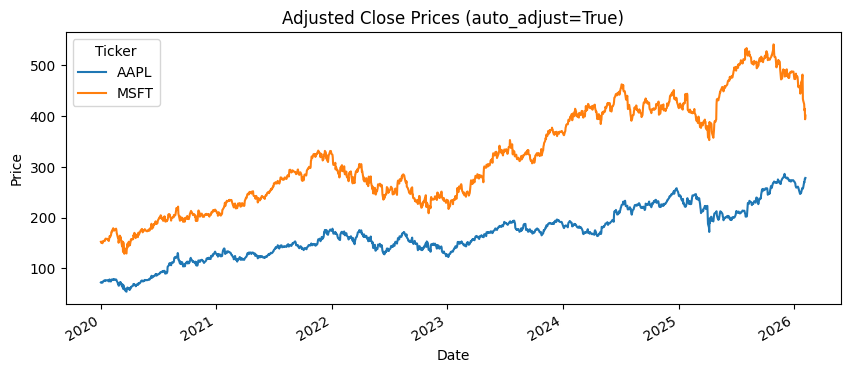

In [38]:
#Prices plot
ax = prices.plot(figsize=(10, 4), title="Adjusted Close Prices (auto_adjust=True)")
ax.set_ylabel("Price")
plt.show()

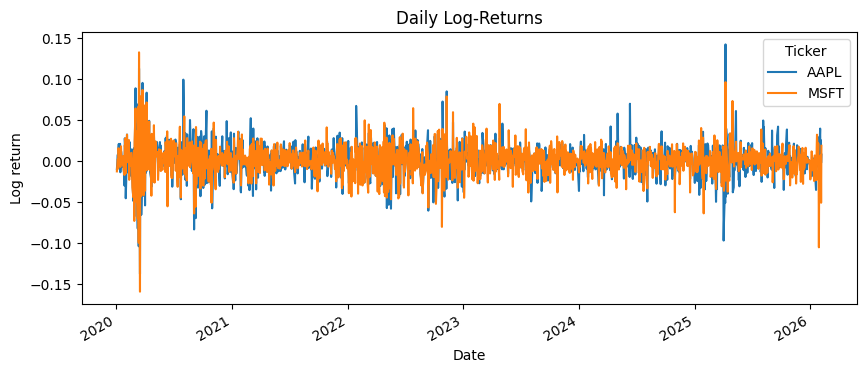

In [39]:
#Return time series
ax = rets.plot(figsize=(10, 4), title="Daily Log-Returns")
ax.set_ylabel("Log return")
plt.show()

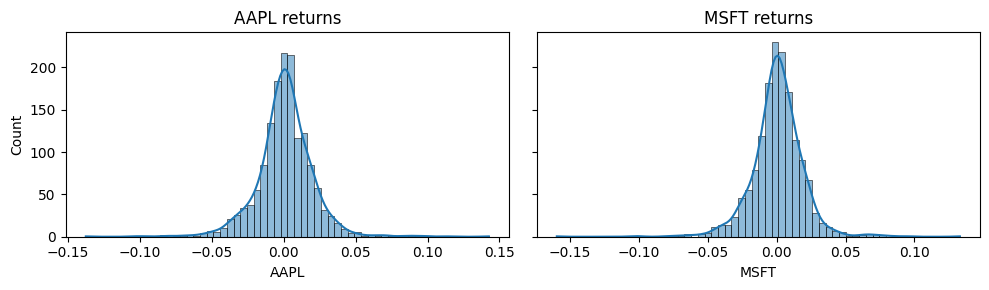

In [40]:
# Return histogram
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for i, t in enumerate(tickers):
    sns.histplot(rets[t], bins=60, kde=True, ax=axes[i])
    axes[i].set_title(f"{t} returns")
plt.tight_layout()
plt.show()

Scatter Plot

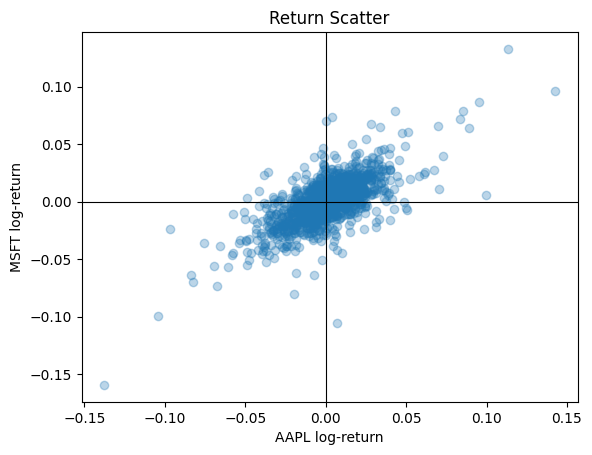

In [41]:
plt.scatter(rets["AAPL"], rets["MSFT"], alpha=0.3)
plt.title("Return Scatter")
plt.xlabel(f"{tickers[0]} log-return")
plt.ylabel(f"{tickers[1]} log-return")
plt.axhline(0, color="black", lw=0.8)
plt.axvline(0, color="black", lw=0.8)
plt.show()

Person and Spearman correlations

a) Pearson corr:

r = cov⁡(X,Y) / σXσY

Note: sensitive to outliers and to non-linear shapes

In [42]:
X_mean = rets["AAPL"].mean()
X_std = rets["AAPL"].std()
X_var = rets["AAPL"].var()

Y_mean = rets["MSFT"].mean()
Y_std = rets["MSFT"].std()
Y_var = rets["MSFT"].var()

XY = rets["AAPL"] * rets["MSFT"]

XY_cov = XY.mean() - X_mean*Y_mean

XY_corr = XY_cov / (X_std * Y_std)
print(XY_corr)


0.693826844206024


In [43]:
print("Pearson corr (returns):", rets[tickers[0]].corr(rets[tickers[1]], method="pearson"))
print("Spearman corr (returns):", rets[tickers[0]].corr(rets[tickers[1]], method="spearman"))

Pearson corr (returns): 0.6942800296039366
Spearman corr (returns): 0.6412607583308741


Copula

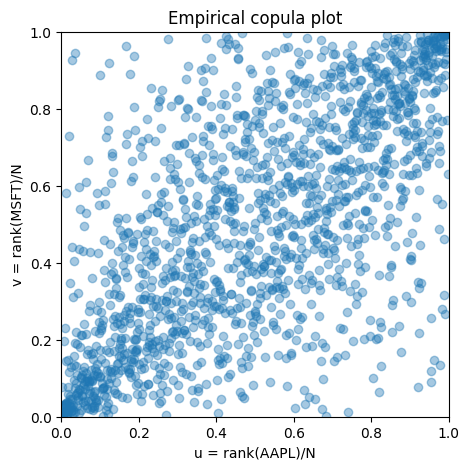

In [44]:
N = len(rets)

# ranks -> [0,1] (percentile ranks)
u = rets["AAPL"].rank(method="average") / N
v = rets["MSFT"].rank(method="average") / N

plt.figure(figsize=(5,5))
plt.scatter(u, v, alpha=0.4)
plt.xlim(0,1); plt.ylim(0,1)
plt.xlabel("u = rank(AAPL)/N")
plt.ylabel("v = rank(MSFT)/N")
plt.title("Empirical copula plot")
plt.show()


**Compare Pearson vs Spearman correlation on returns. Which is larger, and why might they differ?**

Pearson (0.694) > Spearman (0.641)
The relationship between the two return series is quite linear on average, but the pure rank/monotone association is slightly weaker.
​
Pearson measures linear co-movement (how well points line up around a straight line).
​
Spearman does the same idea but on ranks/percentiles (it cares about “up vs down together”, not exact magnitudes).


**In the copula scatter, do you see stronger clustering near (1,1) or (0,0)? What would that suggest about tail dependence (qualitatively)?**

Stronger clustering near (1,1) (and/or (0,0)) means that when one stock is in an extreme quantile, the other is more likely to also be extreme in the same direction

Note: Copulas shows directions, not intensity.